# Hughes et al. (2026) Figure 1 reproduction

This notebook uses the same FaIR parameter as the Hughes et al. 2026 pulse experiment:

- FaIR v2.2.4
- 841-member calibrated constrained v1.4.1 ensemble
- v1.4.0 methane lifetime modification
- SSP1-2.6 baseline
- `ch4_method="Thornhill2021"`
- 2030 pulse
- +1 Gt CO2
- −12.3 Mt CH4 mitigation
- temperature perturbation calculated member-by-member relative to the corresponding SSP1-2.6 baseline member

### Important methane lifetime modification

Hughes et al. state that the overall ensemble uses calibration v1.4.1, but the CH4 response uses the v1.4.0 values for CH4 lifetime and it's sensitivities to temp and chemistry. The v1.4.1 CH4 lifetime parameters were used to match the emissions inventory to atmospheric observations, resulting in an unrealistically long CH4 lifetime. 

The notebook loads the official v1.4.0 `CH4_lifetime.csv` from the FaIR calibration archive and overwrites those methane-lifetime settings after the v1.4.1 calibration has been loaded.
### Two configurations in this version

The primary model (`f`) applies 8.7-year methane lifetime and 1.25× background CH4 emissions. The comparison model (`f_original`) uses the v1.4.0 reference lifetime and unscaled baseline methane emissions. The notebook compares their GWP20 pulse temperature responses and model-implied GWP20/GWP100 values.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fair import FAIR
from fair.interface import fill, initialise
from fair.io import read_properties

from pathlib import Path
Path("../figures").mkdir(parents=True, exist_ok=True)

/opt/anaconda3/envs/vcm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Files and experiment settings

In [2]:
FAIR_PARAMS_141 = "../timeseries-data/input-data/fair/calibrated_constrained_parameters_calibration1.4.1.csv"
FAIR_SPECIES_141 = "../timeseries-data/input-data/fair/species_configs_properties_calibration1.4.1.csv"

# official fair-calibrate v1.4.0 methane-lifetime file
CH4_LIFETIME_140 = "../timeseries-data/input-data/fair/CH4_lifetime_calibration1.4.0.csv"

BASELINE = "ssp126"
PULSE_YEAR = 2030
CO2_PULSE_GT = 1.0
CH4_MITIGATION_MT = {
    "GWP20": -12.3,                              # exact Hughes perturbation
    "GWP100": -1000 * CO2_PULSE_GT / 27.9,
    "GWP500": -1000 * CO2_PULSE_GT / 7.95,}

# Add lifetime and emissions scaling
CH4_BASE_LIFETIME_YR = 8.7 #Baseline is 10.007 yrs 
CH4_EMISSIONS_SCALE = 1.25

START_YEAR = 1750
END_YEAR = 2200

## 2. Load the full SSP1-2.6 baseline

The earlier test notebook used only a few species. That is not appropriate here because the methane-lifetime formulation depends on background chemically reactive species. This version uses the complete FaIR species list and full RCMIP SSP1-2.6 background.

In [3]:
f_base = FAIR(ch4_method="Thornhill2021")
f_base.define_time(START_YEAR, END_YEAR, 1)
f_base.define_scenarios([BASELINE])
f_base.define_configs(["central"])

species, properties = read_properties(filename=FAIR_SPECIES_141)
f_base.define_species(species, properties)
f_base.allocate()
f_base.fill_species_configs(FAIR_SPECIES_141)
f_base.fill_from_rcmip()

# scale baseline methane emissions used throughout the notebook
f_base.emissions.loc[dict(scenario=BASELINE, specie="CH4")].values *= CH4_EMISSIONS_SCALE

print(f"{len(species)} species loaded.")
print(f"CH4 emissions scaled by {CH4_EMISSIONS_SCALE:.3f}")
print(species)

61 species loaded.
CH4 emissions scaled by 1.250
['CO2 FFI', 'CO2 AFOLU', 'CO2', 'CH4', 'N2O', 'Sulfur', 'BC', 'OC', 'NH3', 'NOx', 'VOC', 'CO', 'CFC-11', 'CFC-12', 'CFC-113', 'CFC-114', 'CFC-115', 'HCFC-22', 'HCFC-141b', 'HCFC-142b', 'CCl4', 'CHCl3', 'CH2Cl2', 'CH3Cl', 'CH3CCl3', 'CH3Br', 'Halon-1211', 'Halon-1301', 'Halon-2402', 'CF4', 'C2F6', 'C3F8', 'c-C4F8', 'C4F10', 'C5F12', 'C6F14', 'C7F16', 'C8F18', 'NF3', 'SF6', 'SO2F2', 'HFC-125', 'HFC-134a', 'HFC-143a', 'HFC-152a', 'HFC-227ea', 'HFC-23', 'HFC-236fa', 'HFC-245fa', 'HFC-32', 'HFC-365mfc', 'HFC-4310mee', 'Solar', 'Volcanic', 'Aerosol-radiation interactions', 'Aerosol-cloud interactions', 'Ozone', 'Light absorbing particles on snow and ice', 'Stratospheric water vapour', 'Land use', 'Equivalent effective stratospheric chlorine']


## 3. Set up the 841-member v1.4.1 ensemble

In [4]:
df_configs = pd.read_csv(FAIR_PARAMS_141, index_col=0)
configs = df_configs.index
scenarios = [BASELINE, "co2_pulse", "ch4_mitigation", "net_gwp20", "net_gwp100", "net_gwp500",]
cfc_scenarios = ["cfc11_pulse", "cfc12_pulse"]

# published gwps for cfc crediting experiments
CFC_GWPS = {
    "CFC-11": {"GWP20": 8320, "GWP100": 6230, "GWP500": 2090},
    "CFC-12": {"GWP20": 12700, "GWP100": 12500, "GWP500": 5700}}
cfc_net_scenarios = [
    f"net_{gas.lower().replace('-', '')}_{metric.lower()}"
    for gas, metrics in CFC_GWPS.items() for metric in metrics]
f_scenarios = scenarios + cfc_scenarios + cfc_net_scenarios

f = FAIR(ch4_method="Thornhill2021")
f.define_time(START_YEAR, END_YEAR, 1)
f.define_scenarios(f_scenarios)
f.define_configs(configs)
f.define_species(species, properties)
f.allocate()

# load v1.4.1 defaults and 841 calibrated parameter sets
f.fill_species_configs(FAIR_SPECIES_141)
f.override_defaults(FAIR_PARAMS_141)

fill(f.climate_configs["stochastic_run"], False)
fill(f.climate_configs["use_seed"], False)

print(f"{len(configs)} calibrated ensemble members.")

841 calibrated ensemble members.


## 4. Apply the methane-lifetime parameterization

The CARB experiments retain calibration **v1.4.1** for the ensemble overall but replace the methane-lifetime terms with the full **v1.4.0** set. This avoids the much longer v1.4.1 methane lifetime while retaining the calibrated v1.4.1 climate and carbon-cycle ensemble.

The override includes the v1.4.0 unperturbed lifetime, temperature sensitivity, and chemical sensitivities to CH4, N2O, halocarbons (HC/EESC), NOx, and VOC.


In [5]:
# use the full v1.4.0 methane lifetime calibration, matching the CARB experiments
ch4_v140 = pd.read_csv(CH4_LIFETIME_140).iloc[0]

fill(f.species_configs["unperturbed_lifetime"], CH4_BASE_LIFETIME_YR, specie="CH4")
fill(f.species_configs["lifetime_temperature_sensitivity"], ch4_v140["temp"])
#fill(f.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140["CH4"], specie="CH4") # Currently left out because not included in Hughes
fill(f.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140["N2O"], specie="N2O")
fill(f.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140["HC"], specie="Equivalent effective stratospheric chlorine")
fill(f.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140["NOx"], specie="NOx")
fill(f.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140["VOC"], specie="VOC")

print(f"CH4 base lifetime: {CH4_BASE_LIFETIME_YR:.3f} yr")
print(f"v1.4.0 reference lifetime: {ch4_v140['base']:.3f} yr")


CH4 base lifetime: 8.700 yr
v1.4.0 reference lifetime: 10.007 yr


## 5. Copy SSP1-2.6 into every scenario and add the 2030 perturbations

For each scenario, the complete SSP1-2.6 emissions, concentrations, and prescribed forcings are copied into all 841 configurations. We then change only CO2 and/or CH4 in 2030.

In [6]:
# copy the complete SSP1-2.6 background into every scenario/config
base_emissions = f_base.emissions.sel(scenario=BASELINE, config="central").values
base_concentration = f_base.concentration.sel(scenario=BASELINE, config="central").values
base_forcing = f_base.forcing.sel(scenario=BASELINE, config="central").values

for scen in f_scenarios:
    f.emissions.loc[dict(scenario=scen)].values[:] = base_emissions[:, None, :]
    f.concentration.loc[dict(scenario=scen)].values[:] = base_concentration[:, None, :]
    f.forcing.loc[dict(scenario=scen)].values[:] = base_forcing[:, None, :]

# apply the calibrated forcing scale factors to prescribed solar and volcanic forcing
for sp in ["Solar", "Volcanic"]:
    col = f"forcing_scale[{sp}]"
    if sp in species and col in df_configs.columns:
        original = f.forcing.sel(specie=sp).values.copy()
        scales = df_configs[col].values
        f.forcing.loc[dict(specie=sp)].values[:] = original * scales[None, None, :]

timepoints = np.asarray(f.timepoints, dtype=float)
pulse_time = timepoints[np.argmin(np.abs(timepoints - PULSE_YEAR))]
print("FaIR pulse timepoint:", pulse_time)

# +1 Gt CO2 pulse
f.emissions.loc[dict(timepoints=pulse_time, scenario="co2_pulse", specie="CO2 FFI")].values += CO2_PULSE_GT
# Hughes GWP20 methane-only perturbation retained for diagnostics
f.emissions.loc[dict(timepoints=pulse_time, scenario="ch4_mitigation", specie="CH4")].values += CH4_MITIGATION_MT["GWP20"]
# combined CO2 + CH4 perturbations under each GWP
for gwp, ch4_mt in CH4_MITIGATION_MT.items():
    scen = f"net_{gwp.lower()}"
    f.emissions.loc[dict(timepoints=pulse_time, scenario=scen, specie="CO2 FFI")].values += CO2_PULSE_GT
    f.emissions.loc[dict(timepoints=pulse_time, scenario=scen, specie="CH4")].values += ch4_mt

# add 1 kt emission pulses for each cfc
CFC_PULSE_KT = 1.0
for scen, gas in [("cfc11_pulse", "CFC-11"), ("cfc12_pulse", "CFC-12")]:
    f.emissions.loc[dict(timepoints=pulse_time, scenario=scen, specie=gas)].values += CFC_PULSE_KT

# add gwp-equivalent cfc mitigation and co2 emission pulses
for gas, metrics in CFC_GWPS.items():
    for metric, gwp in metrics.items():
        scen = f"net_{gas.lower().replace('-', '')}_{metric.lower()}"
        cfc_kt = CO2_PULSE_GT * 1e6 / gwp
        f.emissions.loc[dict(timepoints=pulse_time, scenario=scen, specie="CO2 FFI")].values += CO2_PULSE_GT
        f.emissions.loc[dict(timepoints=pulse_time, scenario=scen, specie=gas)].values -= cfc_kt

FaIR pulse timepoint: 2029.5


## 6. Initialise and run FaIR

In [7]:
initialise(f.concentration, f.species_configs["baseline_concentration"])
initialise(f.forcing, 0.0)
initialise(f.temperature, 0.0)
initialise(f.cumulative_emissions, 0.0)
initialise(f.airborne_emissions, 0.0)
initialise(f.ocean_heat_content_change, 0.0)

# restore the prescribed SSP solar/volcanic forcing after initialization
for scen in f_scenarios:
    for sp in ["Solar", "Volcanic"]:
        if sp in species:
            base = f_base.forcing.sel(scenario=BASELINE, config="central", specie=sp).values[:, None]
            scale_col = f"forcing_scale[{sp}]"
            scales = df_configs[scale_col].values if scale_col in df_configs.columns else np.ones(len(configs))
            f.forcing.loc[dict(scenario=scen, specie=sp)].values[:] = base * scales[None, :]

f.run(progress=True)

Running 11774 projections in parallel: 100%|██████████████████████████████████| 450/450 [00:51<00:00,  8.78timesteps/s]


### Original (untuned) comparison run

The model in `f` retains the tuned methane settings. The separate `f_original` uses the v1.4.0 reference lifetime and unscaled background methane emissions. All pulse sizes and other parameters are identical.

In [8]:
# original v1.4.0 methane lifetime and unscaled SSP1-2.6 background
# run separately to preserve the tuned model in f for downstream analyses
f_original = FAIR(ch4_method="Thornhill2021")
f_original.define_time(START_YEAR, END_YEAR, 1)
f_original.define_scenarios(scenarios)
f_original.define_configs(configs)
f_original.define_species(species, properties)
f_original.allocate()
f_original.fill_species_configs(FAIR_SPECIES_141)
f_original.override_defaults(FAIR_PARAMS_141)
fill(f_original.climate_configs["stochastic_run"], False)
fill(f_original.climate_configs["use_seed"], False)

# match the tuned run's v1.4.0 chemical and temperature sensitivities
# change only the base methane lifetime and background methane emissions
fill(f_original.species_configs["unperturbed_lifetime"], float(ch4_v140["base"]), specie="CH4")
fill(f_original.species_configs["lifetime_temperature_sensitivity"], ch4_v140["temp"])
for sp, col in [("N2O", "N2O"), ("Equivalent effective stratospheric chlorine", "HC"),
                ("NOx", "NOx"), ("VOC", "VOC")]:
    fill(f_original.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140[col], specie=sp)
# keep methane self-sensitivity omitted, exactly as in the tuned run

# undo only the baseline methane scaling, not the pulse magnitude
original_background = base_emissions.copy()
original_background[:, list(species).index("CH4")] /= CH4_EMISSIONS_SCALE
for scen in scenarios:
    f_original.emissions.loc[dict(scenario=scen)].values[:] = original_background[:, None, :]
    f_original.concentration.loc[dict(scenario=scen)].values[:] = base_concentration[:, None, :]
    f_original.forcing.loc[dict(scenario=scen)].values[:] = base_forcing[:, None, :]

# apply exactly the same emissions pulses as in the tuned run
pulse_time_original = np.asarray(f_original.timepoints, dtype=float)[np.argmin(
    np.abs(np.asarray(f_original.timepoints, dtype=float) - PULSE_YEAR))]
f_original.emissions.loc[dict(timepoints=pulse_time_original, scenario="co2_pulse", specie="CO2 FFI")].values += CO2_PULSE_GT
f_original.emissions.loc[dict(timepoints=pulse_time_original, scenario="ch4_mitigation", specie="CH4")].values += CH4_MITIGATION_MT["GWP20"]
for gwp, ch4_mt in CH4_MITIGATION_MT.items():
    scen = f"net_{gwp.lower()}"
    f_original.emissions.loc[dict(timepoints=pulse_time_original, scenario=scen, specie="CO2 FFI")].values += CO2_PULSE_GT
    f_original.emissions.loc[dict(timepoints=pulse_time_original, scenario=scen, specie="CH4")].values += ch4_mt

initialise(f_original.concentration, f_original.species_configs["baseline_concentration"])
initialise(f_original.forcing, 0.0)
initialise(f_original.temperature, 0.0)
initialise(f_original.cumulative_emissions, 0.0)
initialise(f_original.airborne_emissions, 0.0)
initialise(f_original.ocean_heat_content_change, 0.0)

# restore the same prescribed solar/volcanic forcing as the tuned run
for scen in scenarios:
    for sp in ["Solar", "Volcanic"]:
        if sp in species:
            base = f_base.forcing.sel(scenario=BASELINE, config="central", specie=sp).values[:, None]
            scale_col = f"forcing_scale[{sp}]"
            scales = df_configs[scale_col].values if scale_col in df_configs.columns else np.ones(len(configs))
            f_original.forcing.loc[dict(scenario=scen, specie=sp)].values[:] = base * scales[None, :]

print(f"Original: CH4 lifetime={ch4_v140['base']:.3f} yr, baseline emissions=1.00x")
print(f"Tuned: CH4 lifetime={CH4_BASE_LIFETIME_YR:.3f} yr, baseline emissions={CH4_EMISSIONS_SCALE:.2f}x")
f_original.run(progress=True)


Original: CH4 lifetime=10.007 yr, baseline emissions=1.00x
Tuned: CH4 lifetime=8.700 yr, baseline emissions=1.25x


Running 5046 projections in parallel: 100%|███████████████████████████████████| 450/450 [00:23<00:00, 19.36timesteps/s]


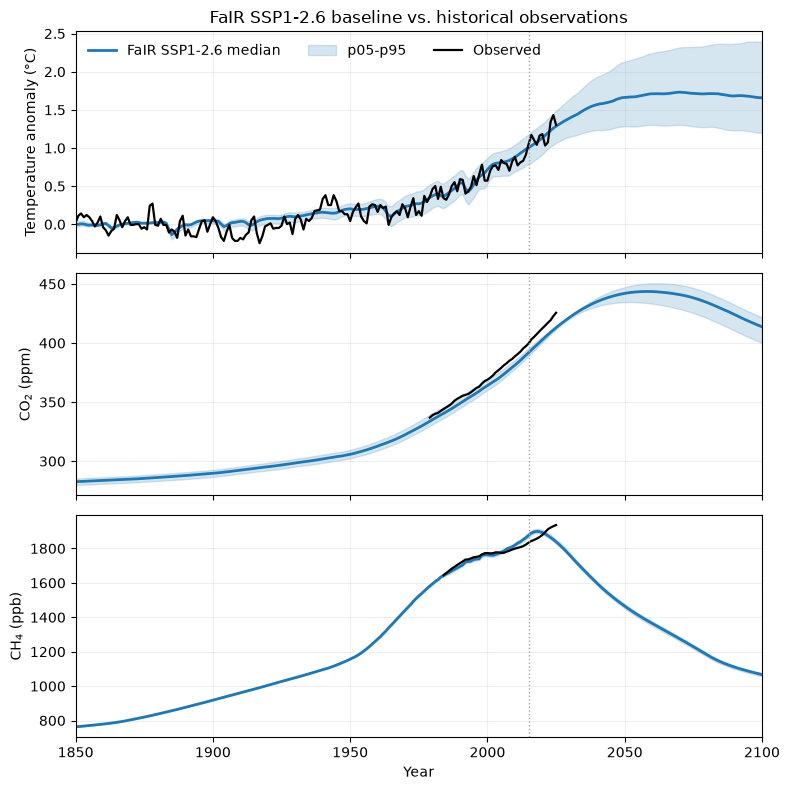

In [9]:
# ----------------------------
# compare ssp1-2.6 baseline with historical observations
# ----------------------------

DATA_DIR = "../timeseries-data/input-data/fair"

temp_obs = pd.read_excel(f"{DATA_DIR}/Temp_NOAA.xlsx")
co2_obs = pd.read_excel(f"{DATA_DIR}/CO2_NOAA_GML.xlsx")
ch4_obs = pd.read_excel(f"{DATA_DIR}/CH4_NOAA_GML.xlsx")

model_years = np.asarray(f.timebounds, dtype=float)

temp_model = f.temperature.sel(scenario=BASELINE, layer=0)
co2_model = f.concentration.sel(scenario=BASELINE, specie="CO2")
ch4_model = f.concentration.sel(scenario=BASELINE, specie="CH4")

# put observed and modeled temperature on the same 1850-1900 anomaly baseline
temp_ref_obs = temp_obs["year"].between(1850, 1900)
temp_obs["anomaly"] = temp_obs["temp"] - temp_obs.loc[temp_ref_obs, "temp"].mean()

temp_ref_model = (model_years >= 1850) & (model_years <= 1900)
temp_model = temp_model - temp_model.isel(timebounds=np.where(temp_ref_model)[0]).mean("timebounds")

def ensemble_stats(da):
    return (da.median("config").values, da.quantile(0.05, dim="config").values, da.quantile(0.95, dim="config").values,)

fig, axes = plt.subplots(3, 1, figsize=(8, 8), sharex=True)

panels = [
    (axes[0], temp_obs["year"], temp_obs["anomaly"], temp_model, "Temperature anomaly (°C)"),
    (axes[1], co2_obs["year"], co2_obs["mean"], co2_model, "CO$_2$ (ppm)"),
    (axes[2], ch4_obs["year"], ch4_obs["mean"], ch4_model, "CH$_4$ (ppb)"),]

for ax, obs_year, obs_value, model_da, ylabel in panels:
    med, lo, hi = ensemble_stats(model_da)
    m = (model_years >= 1850) & (model_years <= 2100)

    line, = ax.plot(model_years[m], med[m], linewidth=2, label="FaIR SSP1-2.6 median")
    ax.fill_between(model_years[m], lo[m], hi[m], color=line.get_color(), alpha=0.18, label="p05-p95")
    ax.plot(obs_year, obs_value, color="black", linewidth=1.6, label="Observed")
    ax.axvline(2015, color="0.65", linestyle=":", linewidth=1)

    ax.set_xlim(1850, 2100)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)

axes[0].set_title("FaIR SSP1-2.6 baseline vs. historical observations")
axes[2].set_xlabel("Year")
axes[0].legend(frameon=False, ncol=3)

fig.tight_layout()
plt.show()

## 7. Calculate member-paired temperature perturbations

In [10]:
baseline_T = f.temperature.sel(scenario=BASELINE, layer=0)

dT_co2 = f.temperature.sel(scenario="co2_pulse", layer=0) - baseline_T
dT_ch4 = f.temperature.sel(scenario="ch4_mitigation", layer=0) - baseline_T
baseline_T = f.temperature.sel(scenario=BASELINE, layer=0)

dT_net = {
    gwp: f.temperature.sel(scenario=f"net_{gwp.lower()}", layer=0) - baseline_T
    for gwp in CH4_MITIGATION_MT}

years = np.asarray(f.timebounds, dtype=float)
plot_years = years + 1
mask = plot_years >= 2028

co2_p50 = dT_co2.median("config").values
ch4_p50 = dT_ch4.median("config").values

net_p05 = {gwp: x.quantile(0.05, dim="config").values
    for gwp, x in dT_net.items()}
net_p50 = {gwp: x.median("config").values
    for gwp, x in dT_net.items()}
net_p95 = {gwp: x.quantile(0.95, dim="config").values
    for gwp, x in dT_net.items()}

def crossover_year(x, y, start=2030):
    m = x >= start
    xx, yy = x[m], y[m]
    for i in range(1, len(yy)):
        if yy[i-1] < 0 <= yy[i]:
            return xx[i-1] + (0 - yy[i-1]) * (xx[i] - xx[i-1]) / (yy[i] - yy[i-1])
    return np.nan

cross_years = {gwp: crossover_year(plot_years, y, start=PULSE_YEAR)
    for gwp, y in net_p50.items()}

post = plot_years >= PULSE_YEAR

for gwp, y in net_p50.items():
    imin = np.nanargmin(y[post])
    print(
        f"{gwp}: CH4 = {CH4_MITIGATION_MT[gwp]:.1f} Mt, "
        f"crossover = {cross_years[gwp]:.1f}, "
        f"peak cooling = {y[post][imin]*1e3:.3f} × 10⁻³ K "
        f"in {plot_years[post][imin]:.0f}")

GWP20: CH4 = -12.3 Mt, crossover = 2044.5, peak cooling = -0.271 × 10⁻³ K in 2034
GWP100: CH4 = -35.8 Mt, crossover = 2061.9, peak cooling = -1.502 × 10⁻³ K in 2034
GWP500: CH4 = -125.8 Mt, crossover = 2109.2, peak cooling = -6.175 × 10⁻³ K in 2034


## 8. Plot Hughes-style result

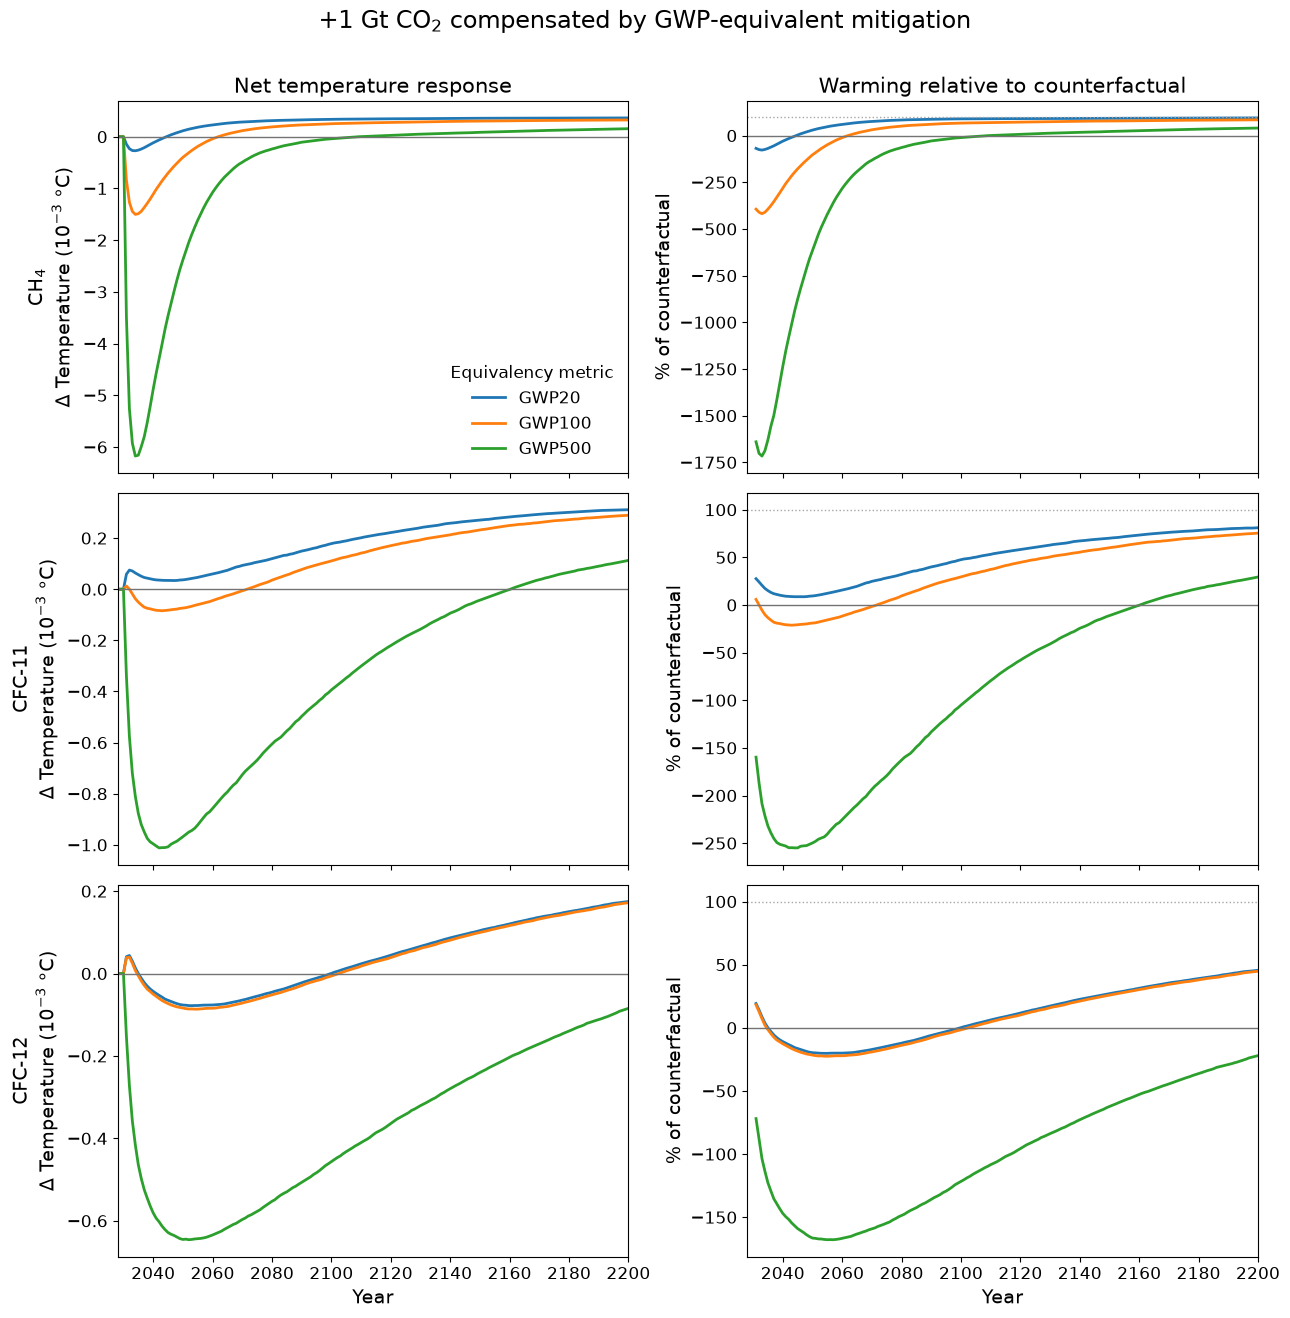

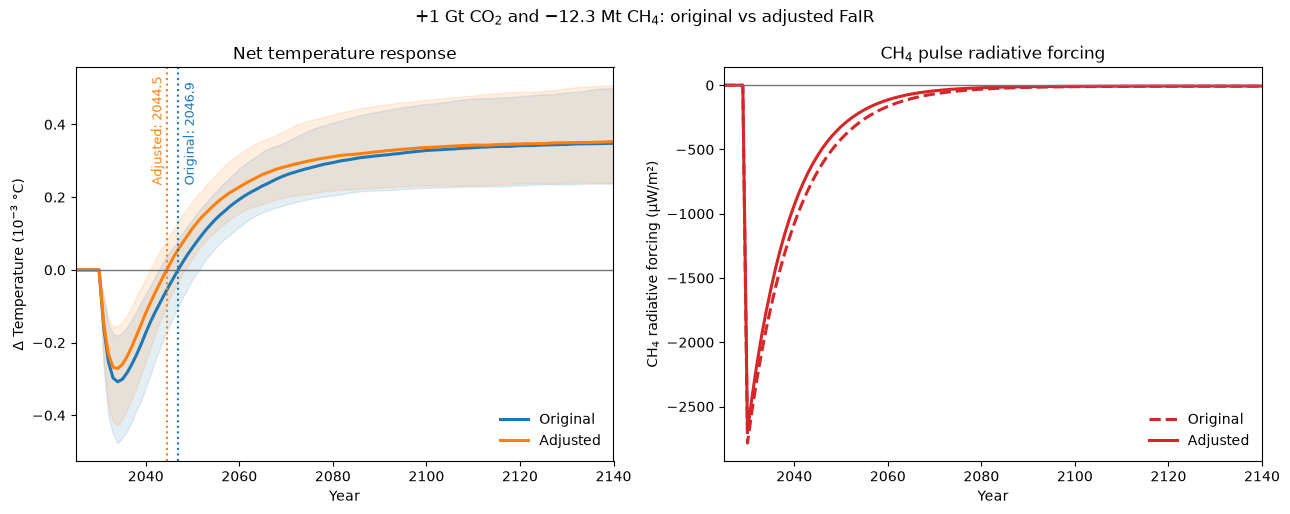

GWP20 pulse crossover: original 2046.9, adjusted 2044.5


In [23]:
# collect net temperature responses for each gas and gwp metric
gas_curves = {"CH$_4$": net_p50}
for gas, metrics in CFC_GWPS.items():
    gas_curves[gas] = {
        metric: (f.temperature.sel(scenario=f"net_{gas.lower().replace('-', '')}_{metric.lower()}", layer=0 ) 
                 - baseline_T).median("config").values
        for metric in metrics}

# six-panel comparison
fig, axes = plt.subplots(3, 2, figsize=(13, 13), sharex=True)

m = (plot_years >= 2028) & (plot_years <= 2200)
valid = np.abs(co2_p50) > 1e-12
colors = {"GWP20": "C0", "GWP100": "C1", "GWP500": "C2"}

for i, (gas, curves) in enumerate(gas_curves.items()):
    ax_temp, ax_pct = axes[i]

    for metric, y in curves.items():
        ax_temp.plot(plot_years[m], y[m] * 1e3,
                     color=colors[metric], linewidth=2, label=metric)

        pct = np.full_like(y, np.nan)
        pct[valid] = 100 * y[valid] / co2_p50[valid]
        ax_pct.plot(plot_years[m], pct[m],
                    color=colors[metric], linewidth=2, label=metric)

    ax_temp.axhline(0, color="0.45", linewidth=1)
    ax_pct.axhline(0, color="0.45", linewidth=1)
    ax_pct.axhline(100, color="0.65", linestyle=":", linewidth=1)

    ax_temp.set_ylabel(f"{gas}\nΔ Temperature ($10^{{-3}}$ °C)")
    ax_pct.set_ylabel("% of counterfactual")

    for ax in (ax_temp, ax_pct):
        ax.set_xlim(2028, 2200)

axes[0, 0].set_title("Net temperature response")
axes[0, 1].set_title("Warming relative to counterfactual")
axes[0, 0].legend(frameon=False, title="Equivalency metric")

for ax in axes[-1]:
    ax.set_xlabel("Year")

fig.suptitle("+1 Gt CO$_2$ compensated by GWP-equivalent mitigation", y=1.01)
fig.tight_layout()
# increase font sizes across all six panels
for ax in axes.flat:
    ax.tick_params(axis="both", labelsize=12)
    ax.xaxis.label.set_size(14)
    ax.yaxis.label.set_size(14)
    ax.title.set_size(15)

axes[0, 0].legend(frameon=False, title="Equivalency metric",
                  fontsize=12, title_fontsize=12)

fig.suptitle("+1 Gt CO$_2$ compensated by GWP-equivalent mitigation",
             fontsize=17, y=1.01)
fig.tight_layout()
fig.savefig("../figures/Figure_S2.png", dpi=300, bbox_inches="tight")
plt.show()

# compare temperature and radiative forcing before and after tuning
orig_baseline_T = f_original.temperature.sel(scenario=BASELINE, layer=0)
orig_dT_gwp20 = f_original.temperature.sel(scenario="net_gwp20", layer=0) - orig_baseline_T
orig_p50 = orig_dT_gwp20.median("config").values
orig_p05 = orig_dT_gwp20.quantile(0.05, dim="config").values
orig_p95 = orig_dT_gwp20.quantile(0.95, dim="config").values
orig_cross = crossover_year(plot_years, orig_p50, start=PULSE_YEAR)

# calculate forcing relative to each model's own baseline
def pulse_forcing(model, scenario):
    baseline = model.forcing_sum.sel(scenario=BASELINE)
    return (model.forcing_sum.sel(scenario=scenario) - baseline).median("config").values

rf_years = np.asarray(f.timebounds, dtype=float)
m = (plot_years >= 2025) & (plot_years <= 2140)
fm = (rf_years >= 2025) & (rf_years <= 2140)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True)

# panel a: net temperature response
ax = axes[0]
ax.plot(plot_years[m], orig_p50[m] * 1e3, color="C0", linewidth=2.2, label="Original")
ax.plot(plot_years[m], net_p50["GWP20"][m] * 1e3, color="C1", linewidth=2.2, label="Adjusted")
# crossover lines with independently adjustable label positions
crossovers = [
    {"year": orig_cross, "color": "C0", "label": "Original", "x_offset": 1, "y_pos": 0.7},
    {"year": cross_years["GWP20"], "color": "C1", "label": "Adjusted", "x_offset": -3.5, "y_pos": 0.7}]
for c in crossovers:
    ax.axvline(c["year"], color=c["color"], linestyle=":", linewidth=1.5)
    ax.text(c["year"] + c["x_offset"], c["y_pos"],
            f'{c["label"]}: {c["year"]:.1f}',
            color=c["color"], rotation=90, va="bottom",
            transform=ax.get_xaxis_transform(), fontsize=9)
ax.fill_between(plot_years[m], orig_p05[m]*1e3, orig_p95[m]*1e3, color="C0", alpha=0.12)
ax.fill_between(plot_years[m], net_p05["GWP20"][m]*1e3, net_p95["GWP20"][m]*1e3, color="C1", alpha=0.12)
ax.axhline(0, color="0.45", linewidth=1)
ax.set_ylabel("Δ Temperature ($10^{-3}$ °C)")
ax.set_title("Net temperature response")
ax.legend(frameon=False)

# panel b: ch4 radiative forcing before and after tuning
ax = axes[1]

for model, name, ls in [(f_original, "Original", "--"), (f, "Adjusted", "-")]:
    ax.plot(rf_years[fm], pulse_forcing(model, "ch4_mitigation")[fm] * 1e6,
            ls, color="C3", linewidth=2.2, label=name)

ax.axhline(0, color="0.45", linewidth=1)
ax.set_ylabel("CH$_4$ radiative forcing (µW/m²)")
ax.set_title("CH$_4$ pulse radiative forcing")
ax.legend(frameon=False)

for ax in axes:
    ax.set_xlim(2025, 2140)
    ax.set_xlabel("Year")

fig.suptitle("+1 Gt CO$_2$ and −12.3 Mt CH$_4$: original vs adjusted FaIR")
fig.tight_layout()
fig.savefig("../figures/Figure_S0.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"GWP20 pulse crossover: original {orig_cross:.1f}, adjusted {cross_years['GWP20']:.1f}")

In [28]:
# calculate timing metrics for figure s2
def upward_cross(x, y, threshold, start=0):
    for i in range(max(1, start + 1), len(x)):
        if np.isfinite(y[i-1:i+1]).all() and y[i-1] < threshold <= y[i]:
            return np.interp(threshold, y[i-1:i+1], x[i-1:i+1]) - PULSE_YEAR
    return np.nan

rows = []
post = (plot_years >= PULSE_YEAR) & (plot_years <= 2200)
x, co2 = plot_years[post], co2_p50[post]

for gas, curves in gas_curves.items():
    for metric, curve in curves.items():
        y = curve[post]
        # find minimum net temperature after year 4
        imin = np.where(x >= PULSE_YEAR + 4)[0][np.nanargmin(y[x >= PULSE_YEAR + 4])]
        # calculate maximum warming rate after peak cooling
        rates = np.diff(y) / np.diff(x)
        rates[:imin] = np.nan
        irate = np.nanargmax(rates) + 1 if np.isfinite(rates).any() else None
        pct = np.divide(100*y, co2, out=np.full_like(y, np.nan), where=np.abs(co2)>1e-12)

        rows.append({
            "Gas": gas.replace("CH$_4$", "CH4"),
            "Metric": metric,
            "Peak cooling": x[imin] - PULSE_YEAR,
            "Peak rate of warming": x[irate] - PULSE_YEAR if irate is not None else np.nan,
            "Crossover": upward_cross(x, y, 0, imin) if y[imin] < 0 else np.nan,
            "50% counterfactual": upward_cross(x, pct, 50, np.nanargmin(pct))
        })

table_s2 = pd.DataFrame(rows).set_index(["Gas", "Metric"])
display(table_s2.round(1))

Peak cooling  Peak rate of warming  Crossover  \
Gas    Metric                                                  
CH4    GWP20            4.0                  10.0       14.5   
       GWP100           4.0                  10.0       31.9   
       GWP500           4.0                  10.0       79.2   
CFC-11 GWP20           17.0                  38.0        NaN   
       GWP100          13.0                  50.0       41.6   
       GWP500          12.0                  39.0      130.2   
CFC-12 GWP20           23.0                  71.0       69.8   
       GWP100          25.0                  61.0       72.4   
       GWP500          22.0                  52.0        NaN   

               50% counterfactual  
Gas    Metric                      
CH4    GWP20                 25.8  
       GWP100                49.4  
       GWP500                 NaN  
CFC-11 GWP20                 74.6  
       GWP100                99.3  
       GWP500                 NaN  
CFC-12 GWP20                  NaN  
       GWP100                 NaN  
       GWP500                 NaN

## 9. Diagnostic plot: separate CO₂ and CH₄ responses

This is not part of Hughes Figure 1, but it is useful for checking whether an unexpected result comes from the CO₂ pulse or the CH₄ mitigation response.

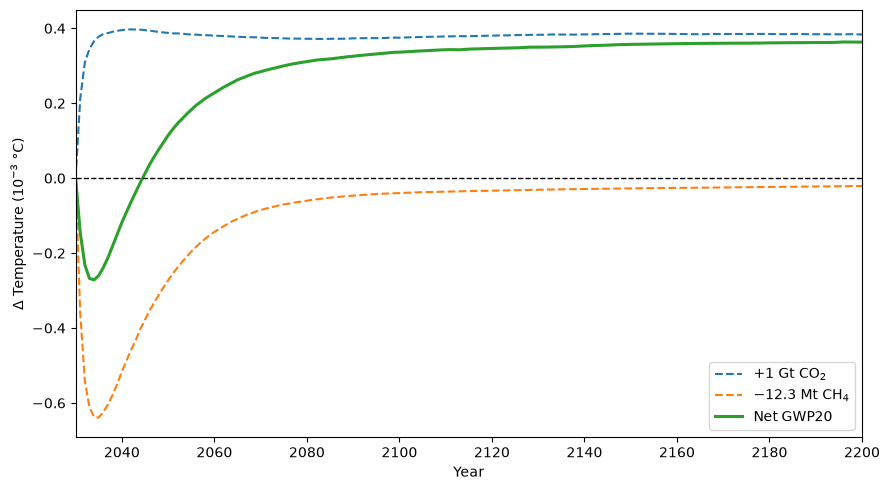

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

m = plot_years >= PULSE_YEAR
ax.plot(plot_years[m], co2_p50[m] * 1e3, "--", label="+1 Gt CO$_2$")
ax.plot(plot_years[m], ch4_p50[m] * 1e3, "--", label="−12.3 Mt CH$_4$")
ax.plot(plot_years[m], net_p50["GWP20"][m] * 1e3, linewidth=2.2, label="Net GWP20")
ax.axhline(0, color="black", linestyle="--", linewidth=1)

ax.set_xlim(PULSE_YEAR, 2200)
ax.set_xlabel("Year")
ax.set_ylabel("Δ Temperature ($10^{-3}$ °C)")
ax.legend()
fig.tight_layout()
plt.show()

In [13]:
# model-implied gwps from the same integrated-forcing pulse experiments
# the same pulses and forcing integration conventions are used for both runs
def calculate_model_gwps(model):
    years = np.asarray(model.timebounds, dtype=float)
    baseline_f = model.forcing_sum.sel(scenario=BASELINE)
    co2_f = (model.forcing_sum.sel(scenario="co2_pulse") - baseline_f).median("config").values
    ch4_f = (model.forcing_sum.sel(scenario="ch4_mitigation") - baseline_f).median("config").values
    results = {}
    for horizon in [20, 100]:
        m = (years >= PULSE_YEAR) & (years <= PULSE_YEAR + horizon)
        co2_agwp = np.trapezoid(co2_f[m], years[m])
        ch4_agwp = np.trapezoid(-ch4_f[m], years[m])
        results[horizon] = (ch4_agwp / -CH4_MITIGATION_MT["GWP20"]) / (co2_agwp / 1000)
    return results

GWP_original = calculate_model_gwps(f_original)
GWP = calculate_model_gwps(f)  # keep tuned values for infrastructure analysis below
GWP100 = GWP[100]
gwp_comparison = pd.DataFrame({
    "Original": {f"GWP{h}": GWP_original[h] for h in [20, 100]},
    "Tuned": {f"GWP{h}": GWP[h] for h in [20, 100]},
})
display(gwp_comparison.round(2))


,Original,Tuned
GWP20,102.47,91.84
GWP100,32.12,27.81


,GWP20,GWP100
Gas,,
CFC-11,7326.3,5214.0
CFC-12,14181.5,13144.7


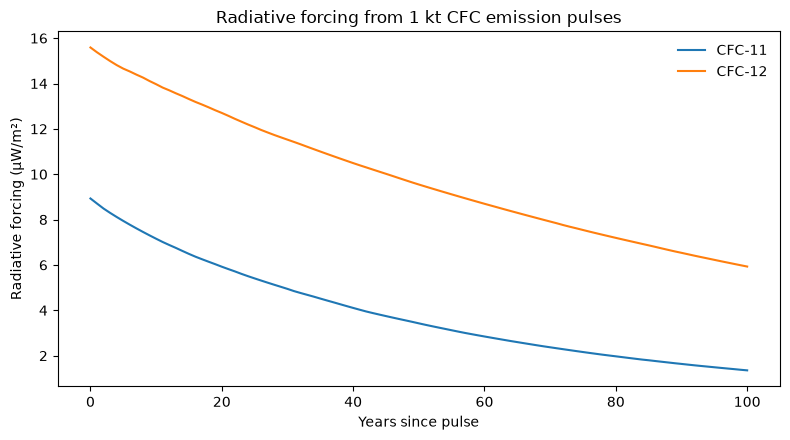

In [14]:
# calculate modeled cfc gwps from integrated radiative forcing
years = np.asarray(f.timebounds, dtype=float)
baseline_f = f.forcing_sum.sel(scenario=BASELINE)

def forcing_response(scenario):
    return (f.forcing_sum.sel(scenario=scenario) - baseline_f).median("config").values

co2_rf = forcing_response("co2_pulse")
cfc_rf = {
    "CFC-11": forcing_response("cfc11_pulse"),
    "CFC-12": forcing_response("cfc12_pulse")
}

results = []
for gas, rf in cfc_rf.items():
    row = {"Gas": gas}
    for horizon in [20, 100]:
        mask = (years >= PULSE_YEAR) & (years <= PULSE_YEAR + horizon)
        co2_agwp = np.trapezoid(co2_rf[mask], years[mask]) / (CO2_PULSE_GT * 1e6)
        cfc_agwp = np.trapezoid(rf[mask], years[mask]) / CFC_PULSE_KT
        row[f"GWP{horizon}"] = cfc_agwp / co2_agwp
    results.append(row)

cfc_gwp_table = pd.DataFrame(results).set_index("Gas")
display(cfc_gwp_table.round(1))

# plot the cfc radiative forcing responses
fig, ax = plt.subplots(figsize=(8, 4.5))
mask = (years >= PULSE_YEAR) & (years <= PULSE_YEAR + 100)

for gas, rf in cfc_rf.items():
    ax.plot(years[mask] - PULSE_YEAR, rf[mask] * 1e6, label=gas)

ax.set(xlabel="Years since pulse", ylabel="Radiative forcing (µW/m²)",
       title="Radiative forcing from 1 kt CFC emission pulses")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Visual reproduction check

Hughes Figure 1 shows, approximately:

- initial cooling after the 2030 pulse
- minimum median cooling around **−0.28 × 10⁻³ °C**
- crossover back through zero around **2046**
- positive warming thereafter
- p05–p95 shading around the median

Those numbers are useful as a visual diagnostic, not hard-coded targets. If this notebook still misses them materially, the next thing to check is the precise FaIR package version and whether Hughes used any additional unpublished preprocessing of the v1.4.0 methane-lifetime configuration.

## 10. CH4 infrastructure crediting test

Here, we test different crediting scenarios for infrastrucutre that provides longterm or theoretically permanent reductions to CH4 emissions. We continue to use the Hughes et al., FaIR parameters for consistency, despite the slight positive bias to 

In [15]:
# ----------------------------
# methane infrastructure crediting scenarios
# ----------------------------

INFRA_START_YEAR = 2030

# annual methane reduction from the infrastructure project, Mt CH4/yr
CH4_REDUCTION_MT_YR = 1.0

# co2 emissions justified by methane credits, gt co2/yr. GWP100 value is based on and calculated using current FaIR configuration
# See section 9.
CO2_CREDIT_GT_YR = CH4_REDUCTION_MT_YR * GWP100 / 1000

# crediting period, additional methane mitigation after crediting
# None means mitigation continues through the end of the FaIR run
infra_scenarios = {
    "credit10_reduce20": (10, 10),
    "credit10_reduce40": (10, 30),
    "credit10_reduce60": (10, 50),
    "credit30_reduce40": (30, 10),
    "credit30_reduce60": (30, 30),
    "credit30_reduce80": (30, 50),}
infra_scenario_names = [BASELINE] + list(infra_scenarios)

for name, (credit_years, extra_years) in infra_scenarios.items():
    mitigation_years = "indefinite" if extra_years is None else credit_years + extra_years
    print(f"{name}: {credit_years} credit years, {mitigation_years} mitigation years")

credit10_reduce20: 10 credit years, 20 mitigation years
credit10_reduce40: 10 credit years, 40 mitigation years
credit10_reduce60: 10 credit years, 60 mitigation years
credit30_reduce40: 30 credit years, 40 mitigation years
credit30_reduce60: 30 credit years, 60 mitigation years
credit30_reduce80: 30 credit years, 80 mitigation years


In [16]:
# ----------------------------
# configure infrastructure fair run
# ----------------------------

f_infra = FAIR(ch4_method="Thornhill2021")
f_infra.define_time(START_YEAR, END_YEAR, 1)
f_infra.define_scenarios(infra_scenario_names)
f_infra.define_configs(configs)
f_infra.define_species(species, properties)
f_infra.allocate()

# same fair calibration as hughes experiment above
f_infra.fill_species_configs(FAIR_SPECIES_141)
f_infra.override_defaults(FAIR_PARAMS_141)

fill(f_infra.climate_configs["stochastic_run"], False)
fill(f_infra.climate_configs["use_seed"], False)

# same v1.4.0 methane lifetime treatment as above
fill(f_infra.species_configs["unperturbed_lifetime"], CH4_BASE_LIFETIME_YR, specie="CH4")
fill(f_infra.species_configs["lifetime_temperature_sensitivity"], ch4_v140["temp"])
fill(f_infra.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140["N2O"], specie="N2O")
fill(f_infra.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140["HC"], specie="Equivalent effective stratospheric chlorine")
fill(f_infra.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140["NOx"], specie="NOx")
fill(f_infra.species_configs["ch4_lifetime_chemical_sensitivity"], ch4_v140["VOC"], specie="VOC")

# copy ssp1-2.6 background into every scenario
base_emissions = f_base.emissions.sel(scenario=BASELINE, config="central").values
base_concentration = f_base.concentration.sel(scenario=BASELINE, config="central").values
base_forcing = f_base.forcing.sel(scenario=BASELINE, config="central").values

for scen in infra_scenario_names:
    f_infra.emissions.loc[dict(scenario=scen)].values[:] = base_emissions[:, None, :]
    f_infra.concentration.loc[dict(scenario=scen)].values[:] = base_concentration[:, None, :]
    f_infra.forcing.loc[dict(scenario=scen)].values[:] = base_forcing[:, None, :]

In [17]:
# ----------------------------
# apply infrastructure perturbations
# ----------------------------

timepoints = np.asarray(f_infra.timepoints, dtype=float)

for scen, (credit_years, extra_years) in infra_scenarios.items():
    credit_end = INFRA_START_YEAR + credit_years
    mitigation_end = END_YEAR + 1 if extra_years is None else credit_end + extra_years
    credit_mask = ((timepoints >= INFRA_START_YEAR) & (timepoints < credit_end))
    mitigation_mask = ((timepoints >= INFRA_START_YEAR) & (timepoints < mitigation_end))

    # credits justify co2 emissions during crediting period
    f_infra.emissions.loc[dict(scenario=scen, specie="CO2 FFI")].values[credit_mask, :] += CO2_CREDIT_GT_YR

    # infrastructure reduces methane while project remains operational
    f_infra.emissions.loc[dict(scenario=scen, specie="CH4")].values[mitigation_mask, :] -= CH4_REDUCTION_MT_YR


# initialize and run
initialise(f_infra.concentration, f_infra.species_configs["baseline_concentration"])
initialise(f_infra.forcing, 0.0)
initialise(f_infra.temperature, 0.0)
initialise(f_infra.cumulative_emissions, 0.0)
initialise(f_infra.airborne_emissions, 0.0)
initialise(f_infra.ocean_heat_content_change, 0.0)

# restore prescribed solar and volcanic forcing
for scen in infra_scenario_names:
    for sp in ["Solar", "Volcanic"]:
        if sp in species:
            base = f_base.forcing.sel( scenario=BASELINE, config="central", specie=sp).values[:, None]
            scale_col = f"forcing_scale[{sp}]"
            scales = ( df_configs[scale_col].values if scale_col in df_configs.columns else np.ones(len(configs)))
            f_infra.forcing.loc[dict(scenario=scen, specie=sp)].values[:] = base * scales[None, :]

f_infra.run(progress=True)

Running 5887 projections in parallel: 100%|███████████████████████████████████| 450/450 [00:25<00:00, 17.90timesteps/s]


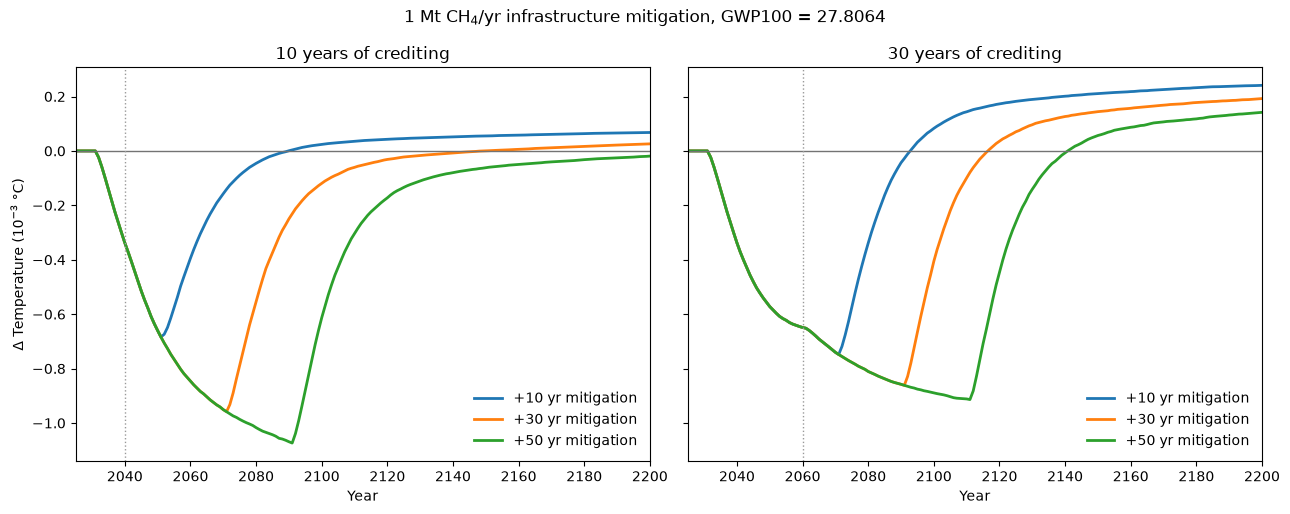

In [18]:
# ----------------------------
# plot infrastructure temperature trajectories
# ----------------------------

infra_years = np.asarray(f_infra.timebounds, dtype=float) + 1

infra_baseline_T = f_infra.temperature.sel(scenario=BASELINE, layer=0)

dT_infra = {scen: f_infra.temperature.sel(scenario=scen, layer=0) - infra_baseline_T
    for scen in infra_scenarios}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)

for ax, credit_years in zip(axes, [10, 30]):

    for scen, (cy, extra_years) in infra_scenarios.items():
        if cy != credit_years:
            continue

        y = dT_infra[scen].median("config").values * 1e3

        label = ("indefinite mitigation"
            if extra_years is None
            else f"+{extra_years} yr mitigation")
        ax.plot(infra_years, y, linewidth=2, label=label)

    ax.axhline(0, color="0.45", linewidth=1)
    ax.axvline(INFRA_START_YEAR + credit_years, color="0.6", linestyle=":", linewidth=1)
    ax.set_xlim(INFRA_START_YEAR - 5, END_YEAR)
    ax.set_xlabel("Year")
    ax.set_title(f"{credit_years} years of crediting")
    ax.legend(frameon=False)

axes[0].set_ylabel("Δ Temperature ($10^{-3}$ °C)")
fig.suptitle(f"1 Mt CH$_4$/yr infrastructure mitigation, GWP100 = {GWP100:g}")

fig.tight_layout()
plt.show()

In [19]:
# ----------------------------
# summarize infrastructure scenarios
# ----------------------------

summary = []

for scen, (credit_years, extra_years) in infra_scenarios.items():

    y = dT_infra[scen].median("config").values
    m = infra_years >= INFRA_START_YEAR

    peak_i = np.nanargmin(y[m])
    cross = crossover_year( infra_years, y, start=INFRA_START_YEAR)

    summary.append({
        "scenario": scen,
        "credit_years": credit_years,
        "extra_mitigation_years": "indefinite" if extra_years is None else extra_years,
        "crossover_year": cross,
        "peak_cooling_mK": y[m][peak_i] * 1e3,
        "peak_cooling_year": infra_years[m][peak_i],})

infra_summary = pd.DataFrame(summary)
infra_summary

,scenario,credit_years,extra_mitigation_years,crossover_year,peak_cooling_mK,peak_cooling_year
0,credit10_reduce20,10,10,2089.838184,-0.683902,2051.0
1,credit10_reduce40,10,30,2149.493742,-0.958462,2071.0
2,credit10_reduce60,10,50,NaN,-1.073634,2091.0
3,credit30_reduce40,30,10,2092.787438,-0.748145,2071.0
4,credit30_reduce60,30,30,2116.457034,-0.861616,2091.0
5,credit30_reduce80,30,50,2140.803486,-0.913837,2111.0



# 11. CMIP7 Climate Scenario Experiments

This analysis examines how the timing of short-lived climate pollutant (SLCP) offset crediting influences climate outcomes under different future warming trajectories.

We use global mean temperature projections from the seven CMIP7 ScenarioMIP pathways (van Vuuren et al., 2026) and the GWP100-equivalent temperature responses for CH4, CFC-11, and CFC-12 calculated in the preceding FaIR pulse experiments.

**Analysis steps:**

1. **Scenario trajectories:** Plot CMIP7 global temperature projections alongside historical observations and identify the year of peak warming for each scenario through 2100.
2. **Crediting timing:** Evaluate hypothetical SLCP credits issued annually from 2030 to 2100, using the previously modeled temperature responses shifted to each issuance year.
3. **Peak temperature effects:** Classify whether each credit produces net cooling or warming at the scenario's baseline peak temperature, accounting for the timing of its crossover from cooling to warming.
4. **Visualization:** Generate heatmaps showing how the sign of the temperature response depends on the SLCP, credit issuance year, and CMIP7 scenario.

**Interpretation:** This initial analysis identifies periods when SLCP crediting would reduce or increase temperature at the baseline peak. It does not yet quantify changes in the actual maximum temperature reached, shifts in peak timing, or effects on warming rates.


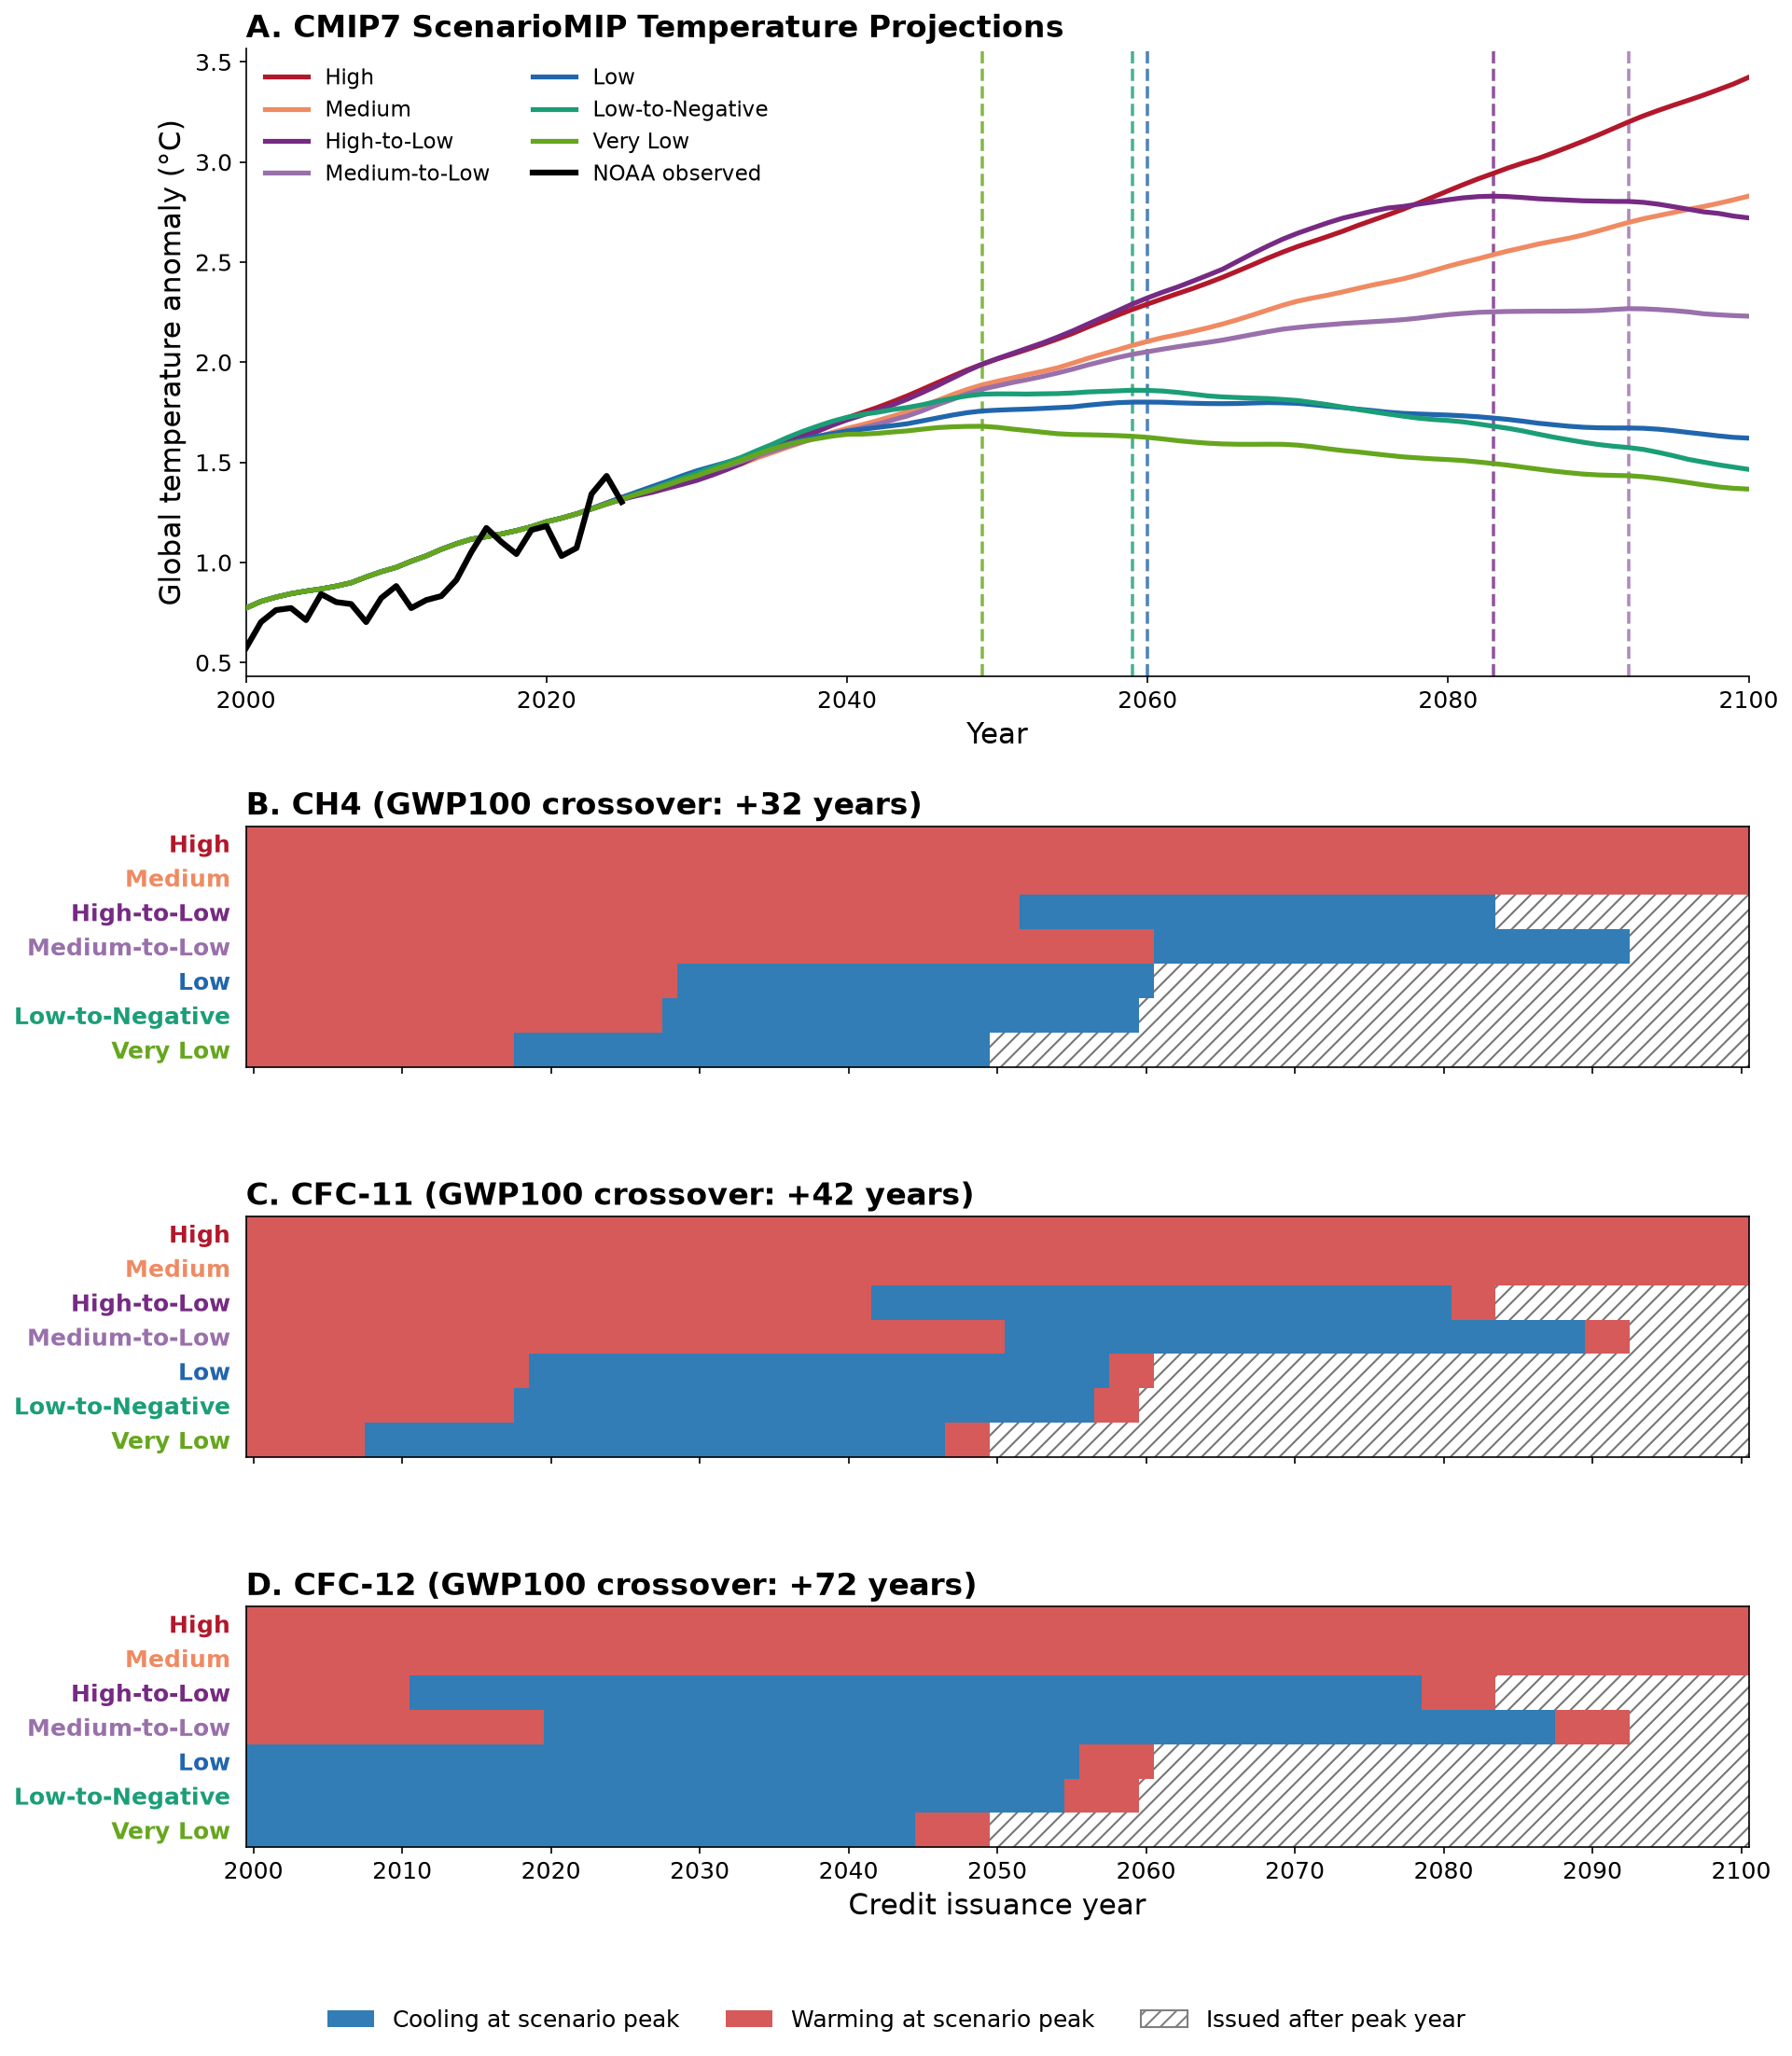

In [35]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch, Rectangle

# load cmip7 scenarios
cmip7 = pd.read_excel("../timeseries-data/input-data/CMIP7_Temp_FaIR_VanVuuren2026.xlsx").set_index("Year")
cmip7.index = cmip7.index.astype(int)

order = ["High", "Medium", "High-to-Low", "Medium-to-Low",
         "Low", "Low-to-Negative", "Very Low"]
cols = sorted(cmip7.columns, key=lambda c: order.index(c.split(" - ")[0]))

# identify peak temperature years through 2100
peaks = {c: int(cmip7.loc[2025:2100, c].idxmax()) for c in cols}
peaks = {c: (y if y < 2100 else None) for c, y in peaks.items()}

# gwp100 crossover years from table s2
crossovers = table_s2.xs("GWP100", level="Metric")["Crossover"].to_dict()
issue_years = np.arange(2000, 2101)

# figure settings
plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 15,
    "axes.titlesize": 16,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.dpi": 150,
    "savefig.dpi": 600
})

blue, red = "#327DB5", "#D65A59"
cmap = ListedColormap([blue, "white", red])
norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], cmap.N)

# consistent scenario colors across all panels
colors = ["#B2182B", "#EF8A62", "#762A83", "#9970AB",
          "#2166AC", "#1B9E77", "#66A61E"]
scenario_colors = dict(zip(cols, colors))

fig, axes = plt.subplots(
    4, 1, figsize=(13, 15),
    gridspec_kw={"height_ratios": [3, 1.15, 1.15, 1.15]}
)

# panel a: cmip7 temperature projections
ax = axes[0]

for col in cols:
    color = scenario_colors[col]
    ax.plot(cmip7.index, cmip7[col], color=color, linewidth=2.5,
            label=col.split(" - ")[0], zorder=3)

    # mark scenario peak year
    if peaks[col] is not None:
        ax.axvline(peaks[col], color=color, linestyle="--",
                   linewidth=1.7, alpha=0.8, zorder=1)

# observed temperatures from earlier notebook analysis
obs = temp_obs[temp_obs["year"].between(2000, 2025)]
ax.plot(obs["year"], obs["anomaly"], color="black", linewidth=3,
        label="NOAA observed", zorder=10)

ax.set(xlim=(2000, 2100), xlabel="Year",
       ylabel="Global temperature anomaly (°C)")
ax.set_title("A. CMIP7 ScenarioMIP Temperature Projections",
             loc="left", fontweight="bold")
ax.legend(frameon=False, ncol=2, loc="upper left", fontsize=11)
ax.grid(False)
ax.spines[["top", "right"]].set_visible(False)

# panels b-d: credit timing heatmaps
for k, (ax, gas) in enumerate(zip(axes[1:], ["CH4", "CFC-11", "CFC-12"])):
    curve = gas_curves["CH$_4$" if gas == "CH4" else gas]["GWP100"]
    values = np.full((len(cols), len(issue_years)), np.nan)

    for i, col in enumerate(cols):
        peak = peaks[col]
        name = col.split(" - ")[0]

        # high and medium assumed to warm at their future peaks
        if name in ["High", "Medium"] or peak is None:
            values[i, :] = 1
            continue

        # credits issued after the peak year are hatched
        after = issue_years > peak
        before = issue_years < peak
        values[i, after] = 0

        # evaluate temperature response before the baseline peak
        ages = peak - issue_years[before]
        dt = np.interp(PULSE_YEAR + ages, plot_years, curve)
        values[i, before] = np.where(
            dt < -1e-12, -1, np.where(dt > 1e-12, 1, 0)
        )

        # give the peak year the same color as the preceding year
        values[i, issue_years == peak] = values[i, issue_years == peak - 1][0]

    ax.imshow(
        values, aspect="auto", cmap=cmap, norm=norm,
        interpolation="nearest",
        extent=[1999.5, 2100.5, len(cols)-0.5, -0.5]
    )

    # hatch issuance years strictly after the peak
    for i, col in enumerate(cols):
        peak = peaks[col]
        if peak is not None and peak < 2100:
            ax.add_patch(Rectangle(
                (peak + 0.5, i - 0.5), 2100 - peak, 1,
                facecolor="none", edgecolor="#777777",
                hatch="///", linewidth=0
            ))

    # match row labels to scenario colors
    ax.set_yticks(range(len(cols)), [c.split(" - ")[0] for c in cols])
    for tick, col in zip(ax.get_yticklabels(), cols):
        tick.set_color(scenario_colors[col])
        tick.set_fontweight("bold")

    ax.set_xlim(1999.5, 2100.5)
    ax.set_title(
        f"{'BCD'[k]}. {gas} (GWP100 crossover: +{crossovers[gas]:.0f} years)",
        loc="left", fontweight="bold"
    )
    ax.tick_params(axis="y", length=0, pad=8)
    ax.set_xticks(np.arange(2000, 2101, 10))
    ax.tick_params(axis="x", labelbottom=(k == 2))

axes[-1].set_xlabel("Credit issuance year", fontsize=15)

# shared heatmap legend
handles = [
    Patch(facecolor=blue, label="Cooling at scenario peak"),
    Patch(facecolor=red, label="Warming at scenario peak"),
    Patch(facecolor="white", edgecolor="gray", hatch="///",
          label="Issued after peak year")
]
fig.legend(handles=handles, loc="lower center", ncol=3,
           frameon=False, fontsize=12, bbox_to_anchor=(0.5, 0.015))

fig.tight_layout(rect=[0, 0.065, 1, 1], h_pad=1.6)

# save publication-quality figure
Path("../figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../figures/Figure_4_CMIP7.png", dpi=600, bbox_inches="tight")
fig.savefig("../figures/Figure_4_CMIP7.pdf", bbox_inches="tight")
plt.show()
